# Circos-Style Genomic Plot

Visualises **log₂ coverage ratio** and **A1 allele fraction** across all scaffolds in a circular layout.

Requires: `matplotlib`, `numpy`

## 1. Imports

In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.colorbar import ColorbarBase
import csv
from collections import defaultdict


## 2. File Paths & Parameters

Edit these to point to your input files.

In [3]:
# ── Input files ───────────────────────────────────────────────────────────────
STRAIN = 'UTEX2827'
#LOG2_PATH    = "12A1_log2_ratios_vs_references.tsv"
LOG2_PATH    = "../../../hybrid_diversity/4_read_mapping/3_deduplicated/2_nuc_and_chloroplast/" + STRAIN + ".log2ratio.tsv"

#ALLELIC_PATH = "12A1_allelic_depth.txt"
ALLELIC_PATH = "../../../hybrid_diversity/5_snp_analyses/3_aims/3_vcf/allelic_depth_per_sample/" + STRAIN + ".allelic_depth.tsv"


OUTPUT_PATH  = 'circos/' + STRAIN + ".circos.pdf"

# ── Plot parameters ────────────────────────────────────────────────────────────
LOG2_CLAMP   = 1.0     # log2 values are clamped to ±this value
LOG2_WINDOW  = 50000   # average log2 bins within this bp window
ALLELIC_BIN  = 20000    # average allelic data within this bp window
FIGSIZE      = 12      # figure width/height in inches
DPI          = 200     # output resolution


## 3. Colour Palettes

All colours live here — easy to customise.

In [4]:
# ── Log2 ratio: gradient ───────────────────────────────────────────────────────
# positions are normalised: val = position * 2 * LOG2_CLAMP - LOG2_CLAMP
# e.g. with LOG2_CLAMP=1: 0.0=-1, 0.1=-0.8, 0.5=0, 0.6=+0.2, 0.9=+0.8, 1.0=+1
LOG2_CMAP = LinearSegmentedColormap.from_list(
    "log2",
    [(0.000, "#364B9A"),   # log2 = -1.00  (loss)
     (0.1, "#4A7BB7"),   # log2 = -0.25  (monosomy)
     (0.3, "#4A7BB7"),   # log2 = -0.25  ← blend starts here
     (0.500, "#EAECCC"),   # log2 =  0.00  (disomy)
     (0.7, "#DD3D2D"),   # log2 = +0.25  ← blend ends here
     (0.9, "#DD3D2D"),   # log2 = +0.79 (trisomy)
     (1.000, "#A50026")],  # log2 = +1.00  (tetrasomy+)
)

def log2_color(val):
    norm = (np.clip(val, -LOG2_CLAMP, LOG2_CLAMP) + LOG2_CLAMP) / (2 * LOG2_CLAMP)
    return LOG2_CMAP(norm)

# ── A1 fraction: gradient with hard boundaries ─────────────────────────────────
ALLELIC_CMAP = LinearSegmentedColormap.from_list(
    "allelic",
    [(0.00, "#004488"),   # A1 frac = 0.00
     (0.33, "#004488"),   # A1 frac = 0.33  ← hard boundary
     (0.50, "#DDAA33"),   # A1 frac = 0.50
     (0.67, "#BB5566"),   # A1 frac = 0.67  ← hard boundary
     (1.00, "#BB5566")],  # A1 frac = 1.00
)

# ── Structural colours ─────────────────────────────────────────────────────────
COLOR_SCAFFOLD   = "#111111"   # scaffold arc fill
COLOR_RING_BG    = "#f4f6fc"   # ring background fill
COLOR_RING_EDGE  = "#dde2f0"   # ring background border
COLOR_BASELINE   = "#111111"   # 0 / 0.5 reference lines
COLOR_SCAF_LABEL = "#445566"   # scaffold number text
COLOR_RING_LABEL = "#5560a0"   # ring label text


## 4. Load Data

In [5]:
def load_log2(path, window_size=LOG2_WINDOW):
    bins = defaultdict(list)
    with open(path) as f:
        reader = csv.DictReader(f, delimiter="\t")
        val_col = [c for c in reader.fieldnames if c not in ("chr","start","end")][0]
        for row in reader:
            try:
                chrom = row["chr"]
                start = int(row["start"])
                end   = int(row["end"])
                val   = float(row[val_col])
                mid   = (start + end) // 2
                bins[(chrom, mid // window_size)].append((mid, val))
            except (ValueError, KeyError):
                pass
    rows = []
    for (chrom, _), pts in bins.items():
        mean_pos = int(np.mean([p for p, v in pts]))
        mean_val = np.mean([v for p, v in pts])
        rows.append((chrom, mean_pos, mean_pos, mean_val))
    return rows


def load_allelic(path, bin_size=ALLELIC_BIN):
    bins = defaultdict(list)
    with open(path) as f:
        reader = csv.DictReader(f, delimiter="\t")
        for row in reader:
            try:
                chrom = row["CHROM"]
                pos   = int(row["POS"])
                val   = float(row["A1_frac"])
                bins[(chrom, pos // bin_size)].append((pos, val))
            except (ValueError, KeyError):
                pass
    rows = []
    for (chrom, _), pts in bins.items():
        mean_pos = int(np.mean([p for p, v in pts]))
        mean_val = np.mean([v for p, v in pts])
        rows.append((chrom, mean_pos, mean_val))
    return rows


log2_rows    = load_log2(LOG2_PATH)
allelic_rows = load_allelic(ALLELIC_PATH)

print(f"Log2 bins    : {len(log2_rows):,}")
print(f"Allelic pts  : {len(allelic_rows):,}")


Log2 bins    : 1,790
Allelic pts  : 4,283


## 5. Build Genome Layout

In [6]:
def build_layout(log2_rows, allelic_rows, gap_fraction=0.004):
    import re
    sizes = {}
    for chrom, start, end, _ in log2_rows:
        sizes[chrom] = max(sizes.get(chrom, 0), end)
    for chrom, pos, _ in allelic_rows:
        sizes[chrom] = max(sizes.get(chrom, 0), pos)

    def sort_key(s):
        parts = re.split(r"(\d+)", s)
        return [int(p) if p.isdigit() else p for p in parts]

    scaffolds = sorted(sizes.keys(), key=sort_key)
    total_bp  = sum(sizes[s] for s in scaffolds)
    gap_bp    = total_bp * gap_fraction

    cum = {}
    acc = 0
    for s in scaffolds:
        cum[s] = acc
        acc += sizes[s] + gap_bp

    return scaffolds, sizes, cum, acc


def bp_to_angle(chrom, pos, cum, total, offset=0):
    """Genomic position → radians, clockwise from 12 o'clock."""
    return -(cum[chrom] + pos) / total * 2 * np.pi - np.pi / 2 + offset


scaffolds, sizes, cum, total = build_layout(log2_rows, allelic_rows)
print(f"Scaffolds    : {len(scaffolds)}")
print("  " + ", ".join(scaffolds))


Scaffolds    : 29
  scaf1, scaf2, scaf3, scaf4, scaf5, scaf6, scaf7, scaf8, scaf9, scaf10, scaf11, scaf12, scaf13, scaf14, scaf15, scaf16, scaf17, scaf18, scaf19, scaf20, scaf21, scaf22, scaf23, scaf24, scaf25, scaf26, scaf27, scaf28, scaf29


## 6. Drawing Helpers

In [7]:
def draw_arc(ax, r_in, r_out, a0, a1, color, alpha=1.0, n=200):
    angles = np.linspace(a0, a1, n)
    xs = np.concatenate([np.cos(angles) * r_out, np.cos(angles[::-1]) * r_in])
    ys = np.concatenate([np.sin(angles) * r_out, np.sin(angles[::-1]) * r_in])
    ax.fill(xs, ys, color=color, lw=0, alpha=alpha, zorder=1)


def draw_ring_background(ax, scaffolds, sizes, cum, total, r_in, r_out):
    for s in scaffolds:
        a0 = bp_to_angle(s, 0,        cum, total, ROTATION_OFFSET)
        a1 = bp_to_angle(s, sizes[s], cum, total, ROTATION_OFFSET)
        draw_arc(ax, r_in, r_out, a0, a1, color=COLOR_RING_BG)
        for r in (r_in, r_out):
            angles = np.linspace(a0, a1, 200)
            ax.plot(np.cos(angles)*r, np.sin(angles)*r,
                    color=COLOR_RING_EDGE, lw=0.4, zorder=2)


def draw_baseline(ax, scaffolds, sizes, cum, total, r, lw=0.6):
    for s in scaffolds:
        a0 = bp_to_angle(s, 0,        cum, total, ROTATION_OFFSET)
        a1 = bp_to_angle(s, sizes[s], cum, total, ROTATION_OFFSET)
        angles = np.linspace(a0, a1, 300)
        ax.plot(np.cos(angles)*r, np.sin(angles)*r,
                color=COLOR_BASELINE, lw=lw, zorder=7)
        

## 7. Draw the Plot

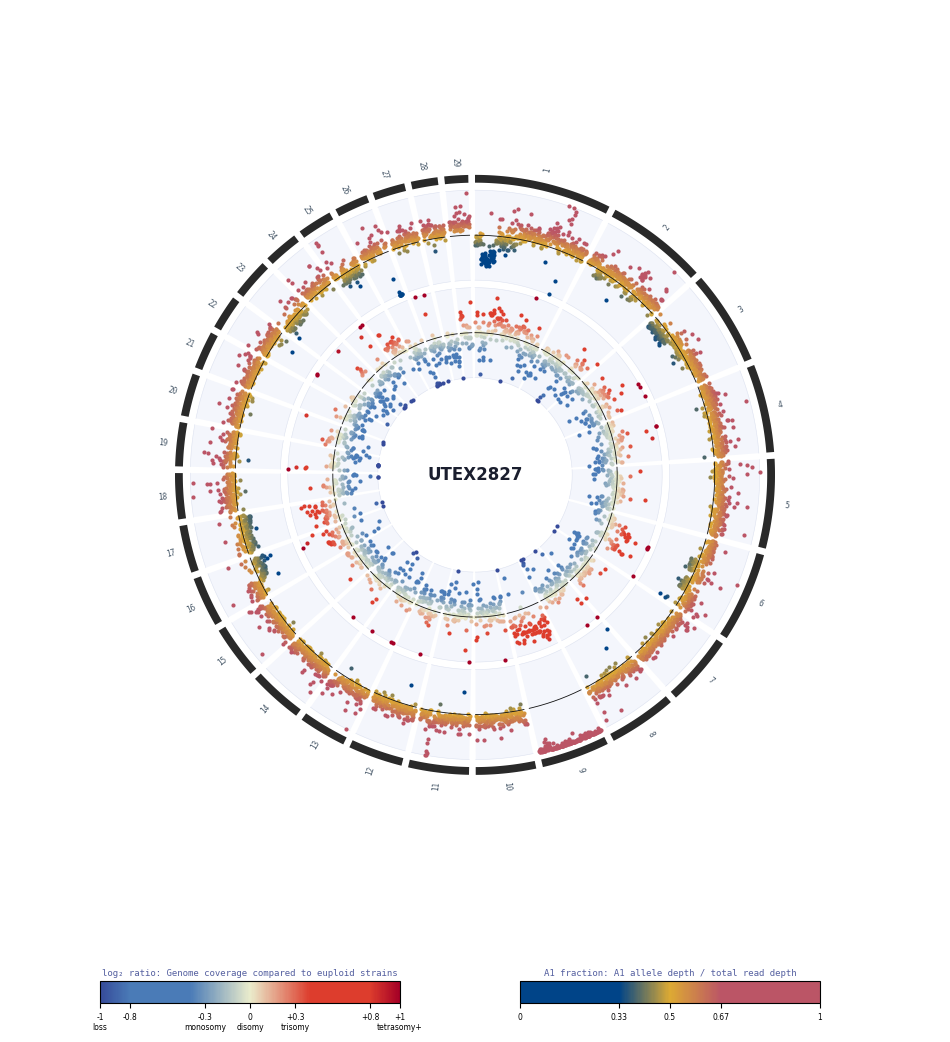

In [8]:
# ── Rotation ───────────────────────────────────────────────────────────────────
ROTATION_OFFSET = np.pi   # rotate ~180° so scaf1 starts near 12 o'clock

# ── Ring radii (fractions of 1) ────────────────────────────────────────────────
R_SCAF_OUT = 1.000
R_SCAF_IN  = 0.974
GAP        = 0.025
RING_W     = 0.30
R_AL_OUT   = R_SCAF_IN  - GAP   # allelic outermost data ring
R_AL_IN    = R_AL_OUT   - RING_W
R_LOG2_OUT = R_AL_IN    - GAP   # log2 innermost data ring
R_LOG2_IN  = R_LOG2_OUT - RING_W

fig, ax = plt.subplots(figsize=(FIGSIZE, FIGSIZE), facecolor="white")
ax.set_aspect("equal")
ax.axis("off")

# ── Scaffold track ─────────────────────────────────────────────────────────────
for s in scaffolds:
    a0 = bp_to_angle(s, 0,        cum, total, ROTATION_OFFSET)
    a1 = bp_to_angle(s, sizes[s], cum, total, ROTATION_OFFSET)
    draw_arc(ax, R_SCAF_IN, R_SCAF_OUT, a0, a1, color=COLOR_SCAFFOLD, alpha=0.9)

for s in scaffolds:
    a0  = bp_to_angle(s, 0,        cum, total, ROTATION_OFFSET)
    a1  = bp_to_angle(s, sizes[s], cum, total, ROTATION_OFFSET)
    mid = (a0 + a1) / 2
    lr  = R_SCAF_OUT + 0.045
    lx, ly = np.cos(mid) * lr, np.sin(mid) * lr
    deg = np.degrees(mid)
    rot = deg if -90 <= deg <= 90 else deg + 180
    ax.text(lx, ly, s.replace("scaf", ""),
            ha="center", va="center", fontsize=5.5,
            color=COLOR_SCAF_LABEL, rotation=rot,
            rotation_mode="anchor", fontfamily="monospace", zorder=8)

# ── Allelic fraction ring (outer) ──────────────────────────────────────────────
draw_ring_background(ax, scaffolds, sizes, cum, total, R_AL_IN, R_AL_OUT)

r_al = lambda v: R_AL_IN + np.clip(v, 0, 1) * (R_AL_OUT - R_AL_IN)
draw_baseline(ax, scaffolds, sizes, cum, total, r_al(0.5))

vals_al   = np.array([v for _, _, v in allelic_rows])
colors_al = ALLELIC_CMAP(vals_al)

for (chrom, pos, val), col in zip(allelic_rows, colors_al):
    if chrom not in cum:
        continue
    a = bp_to_angle(chrom, pos, cum, total, ROTATION_OFFSET)
    r = r_al(val)
    ax.plot(np.cos(a)*r, np.sin(a)*r, "o",
            color=col, ms=3.0, markeredgewidth=0, zorder=5)

# ax.text(0, -(R_AL_IN + R_AL_OUT)/2, "A1 frac",
#         ha="center", va="center", fontsize=6,
#         color=COLOR_RING_LABEL, fontfamily="monospace", zorder=9)

# ── Log2 ratio ring (inner) ────────────────────────────────────────────────────
draw_ring_background(ax, scaffolds, sizes, cum, total, R_LOG2_IN, R_LOG2_OUT)

r_log2 = lambda v: (
    R_LOG2_IN + (np.clip(v, -LOG2_CLAMP, LOG2_CLAMP) + LOG2_CLAMP)
    / (2 * LOG2_CLAMP) * (R_LOG2_OUT - R_LOG2_IN)
)
draw_baseline(ax, scaffolds, sizes, cum, total, r_log2(0))

for chrom, start, end, val in log2_rows:
    if chrom not in cum:
        continue
    a = bp_to_angle(chrom, (start + end) / 2, cum, total, ROTATION_OFFSET)
    r = r_log2(val)
    ax.plot(np.cos(a)*r, np.sin(a)*r, "o",
            color=log2_color(val), ms=3.0, markeredgewidth=0, zorder=5)

# ax.text(0, -(R_LOG2_IN + R_LOG2_OUT)/2, "log\u2082 ratio",
#         ha="center", va="center", fontsize=6,
#         color=COLOR_RING_LABEL, fontfamily="monospace", zorder=9)

# ── Centre label ───────────────────────────────────────────────────────────────
ax.text(0, 0, STRAIN, ha="center", va="center",
        fontsize=12, fontweight="bold", color="#1a1e2e", zorder=9)

# ── Legend colorbars ───────────────────────────────────────────────────────────
fig.subplots_adjust(bottom=0.08)

ax_log2 = fig.add_axes([0.20, 0.04, 0.25, 0.018])
cb_log2 = ColorbarBase(ax_log2, cmap=LOG2_CMAP,
                        norm=Normalize(vmin=-LOG2_CLAMP, vmax=LOG2_CLAMP),
                        orientation="horizontal")
cb_log2.set_ticks([-1, -0.8, -0.3, 0, 0.3, 0.8, 1])
cb_log2.set_ticklabels(["-1\nloss", "-0.8", "-0.3\nmonosomy", "0\ndisomy",
                         "+0.3\ntrisomy", "+0.8", "+1\ntetrasomy+"])
cb_log2.ax.tick_params(labelsize=5.5)
cb_log2.ax.set_title("log\u2082 ratio: Genome coverage compared to euploid strains", fontsize=6.5, color=COLOR_RING_LABEL,
                      fontfamily="monospace", pad=4)

ax_al = fig.add_axes([0.55, 0.04, 0.25, 0.018])
cb_al = ColorbarBase(ax_al, cmap=ALLELIC_CMAP,
                     norm=Normalize(vmin=0, vmax=1),
                     orientation="horizontal")
cb_al.set_ticks([0, 0.33, 0.5, 0.67, 1])
cb_al.set_ticklabels(["0", "0.33", "0.5", "0.67", "1"])
cb_al.ax.tick_params(labelsize=5.5)
cb_al.ax.set_title("A1 fraction: A1 allele depth / total read depth", fontsize=6.5, color=COLOR_RING_LABEL,
                    fontfamily="monospace", pad=4)

ax.set_xlim(-1.55, 1.55)
ax.set_ylim(-1.55, 1.55)
plt.show()

## 8. Save to File

In [9]:
fig.savefig(OUTPUT_PATH, dpi=DPI, bbox_inches="tight", facecolor="white")
print(f"Saved → {OUTPUT_PATH}")


Saved → circos/UTEX2827.circos.pdf


In [10]:
# ── Scaffolds to plot ──────────────────────────────────────────────────────────
#SCAFFOLDS_OF_INTEREST = ["scaf22"]   # ← add any scaffolds here
SCAFFOLDS_OF_INTEREST = scaffolds   # all scaffolds; replace with e.g. ["scaf8"] to subset

# ── Plot parameters ────────────────────────────────────────────────────────────
LOG2_CLAMP     = None    # None = full data range, or set e.g. 1.0 to clamp
LINEAR_WINDOW  = 10000   # log2 averaging window for linear plots (bp)
LINEAR_BIN     = 1000    # allelic fraction bin size for linear plots (bp)
LINEAR_FIGSIZE_HEIGHT = 4      # height per scaffold in inches
LINEAR_MB_PER_INCH    = 0.5   # ← adjust this to make plots wider or narrower
LINEAR_OUTPUT = "linear/{strain}_{scaffold}.linear.pdf"  # {strain} and {scaffold} will be replaced

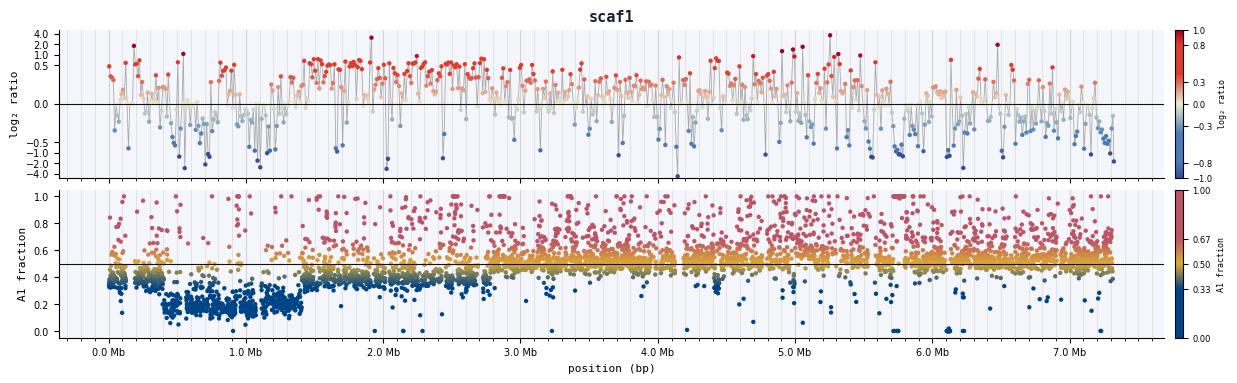

Saved → linear/UTEX2827_scaf1.linear.pdf


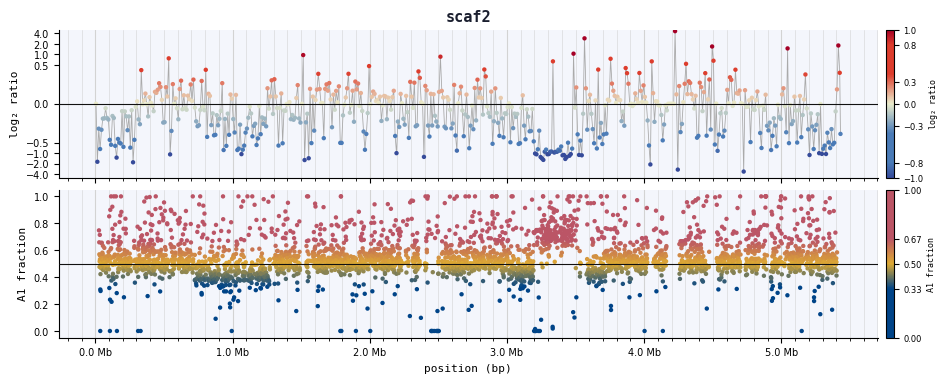

Saved → linear/UTEX2827_scaf2.linear.pdf


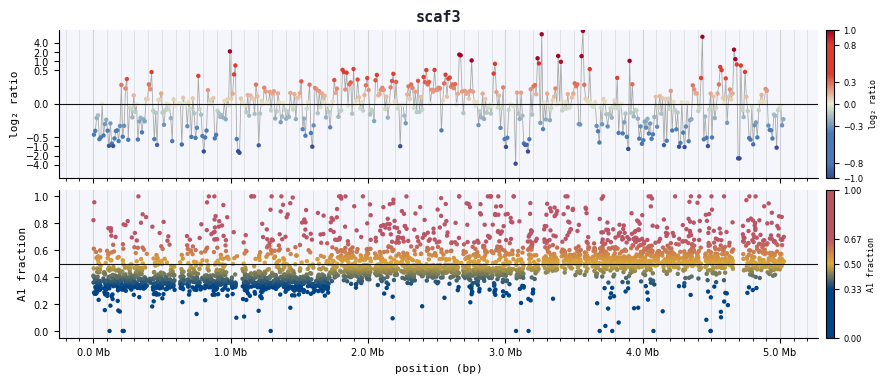

Saved → linear/UTEX2827_scaf3.linear.pdf


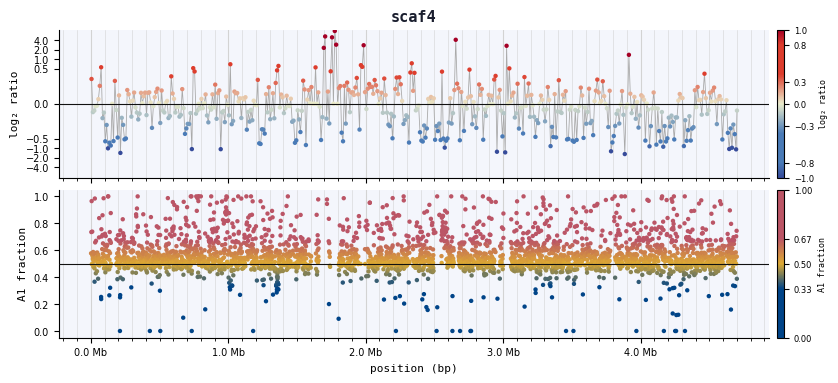

Saved → linear/UTEX2827_scaf4.linear.pdf


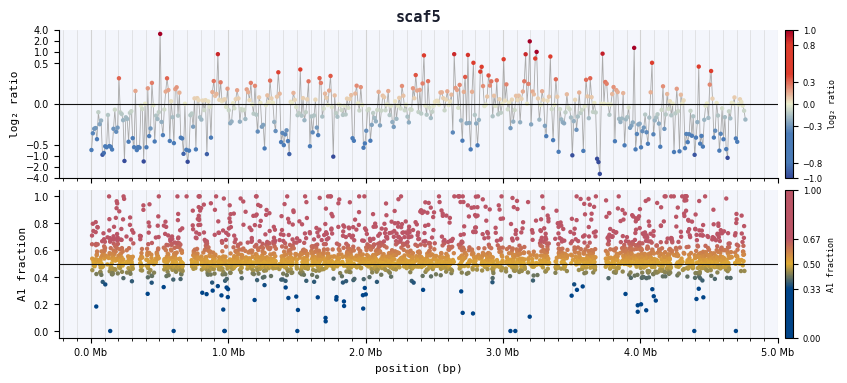

Saved → linear/UTEX2827_scaf5.linear.pdf


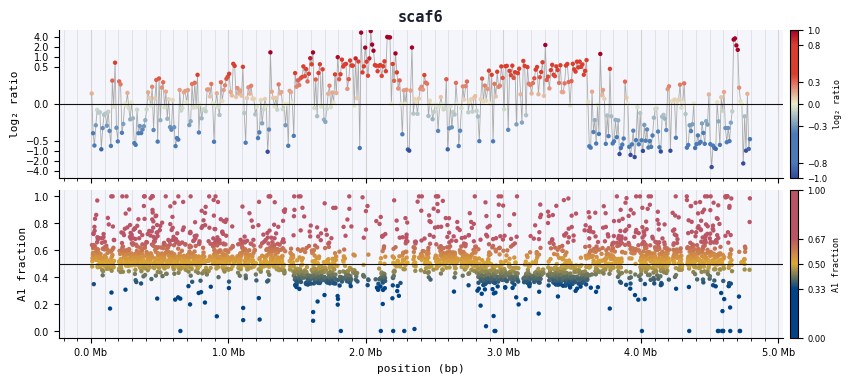

Saved → linear/UTEX2827_scaf6.linear.pdf


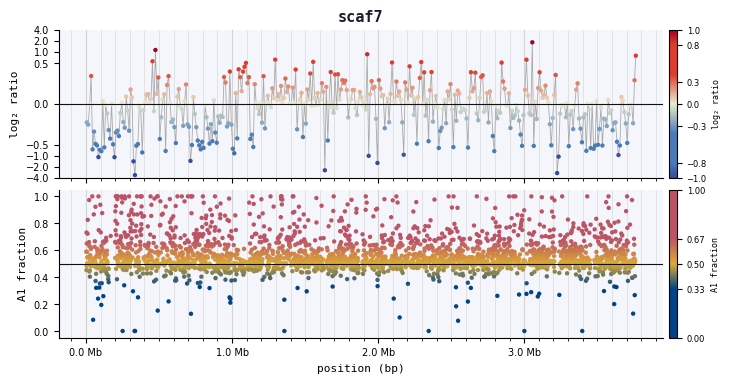

Saved → linear/UTEX2827_scaf7.linear.pdf


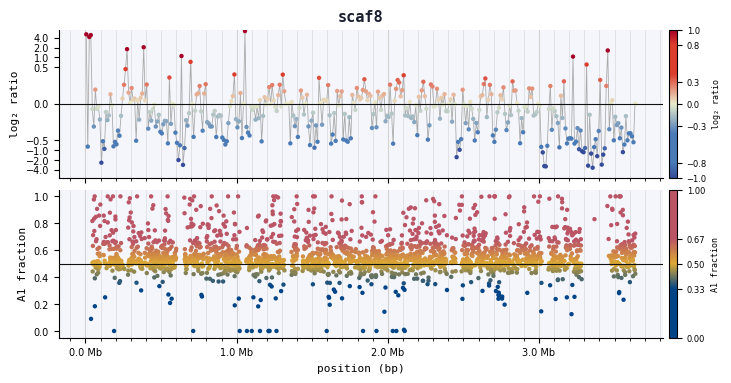

Saved → linear/UTEX2827_scaf8.linear.pdf


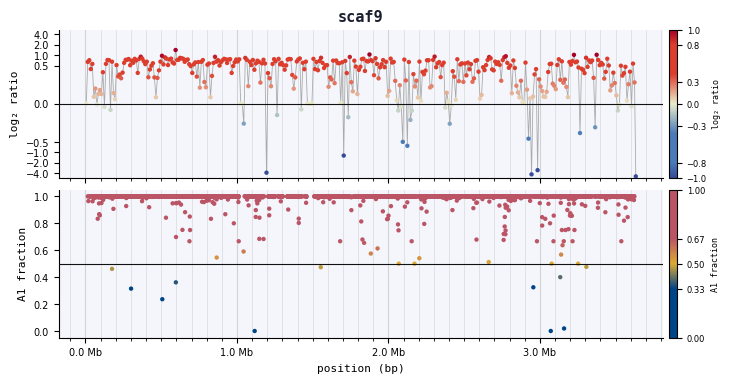

Saved → linear/UTEX2827_scaf9.linear.pdf


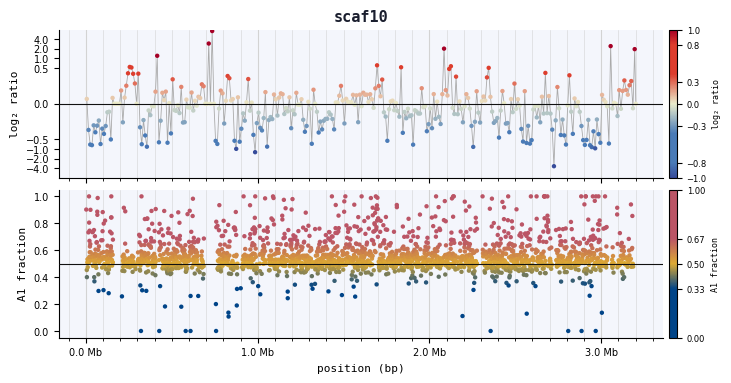

Saved → linear/UTEX2827_scaf10.linear.pdf


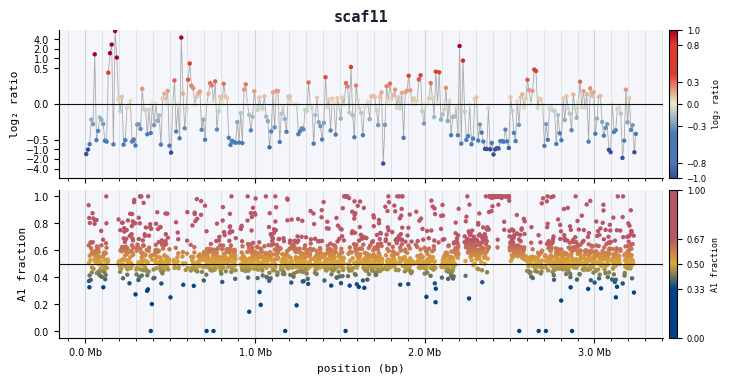

Saved → linear/UTEX2827_scaf11.linear.pdf


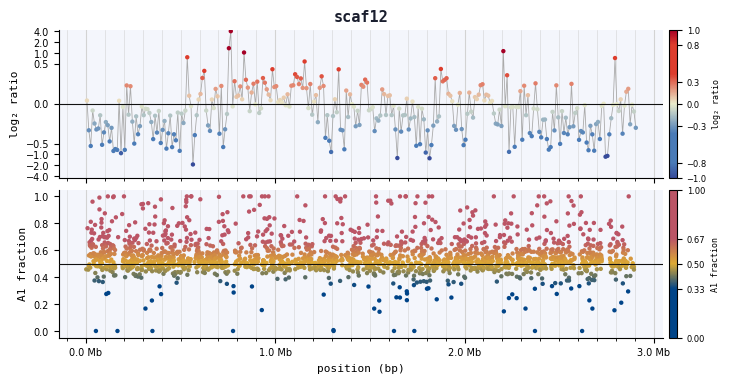

Saved → linear/UTEX2827_scaf12.linear.pdf


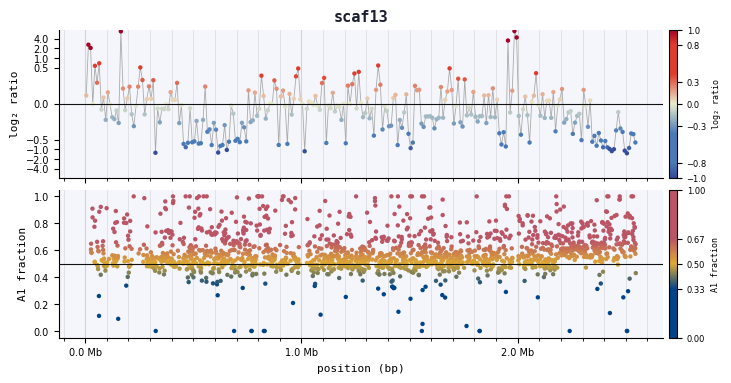

Saved → linear/UTEX2827_scaf13.linear.pdf


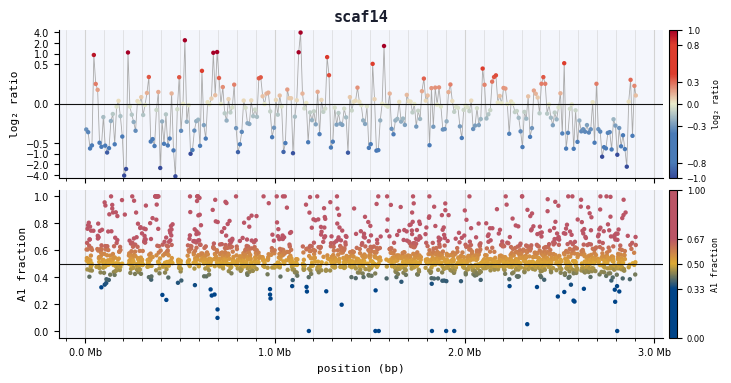

Saved → linear/UTEX2827_scaf14.linear.pdf


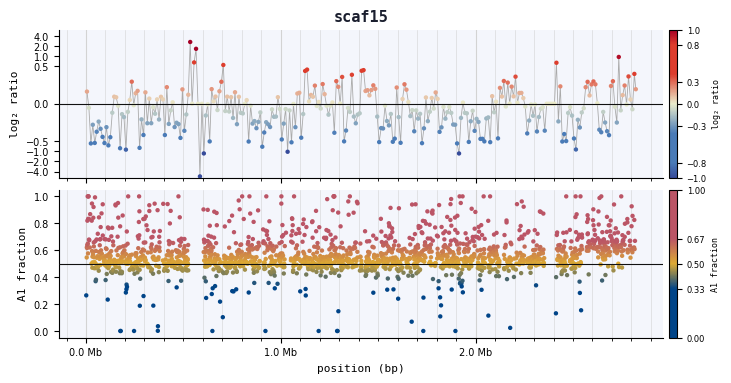

Saved → linear/UTEX2827_scaf15.linear.pdf


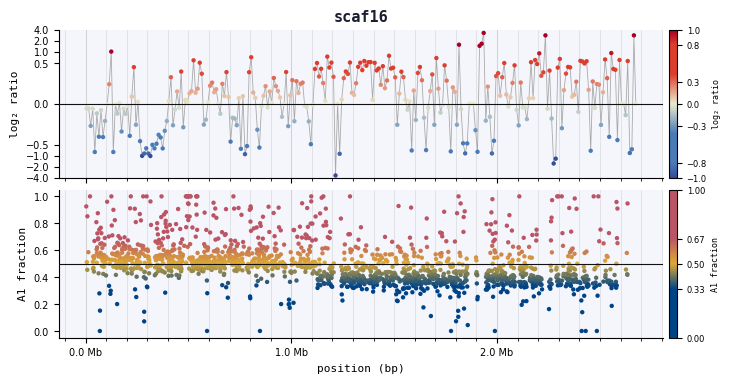

Saved → linear/UTEX2827_scaf16.linear.pdf


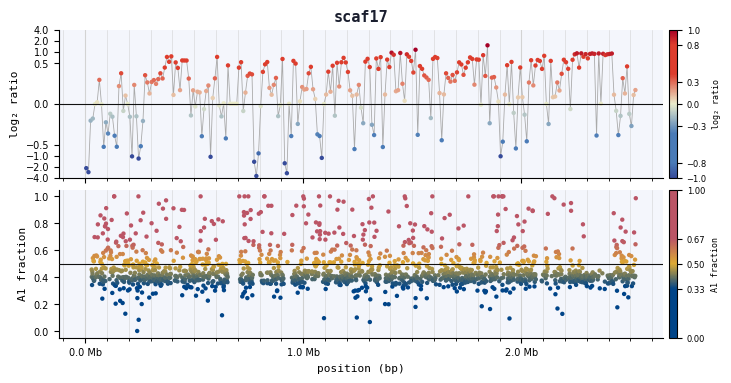

Saved → linear/UTEX2827_scaf17.linear.pdf


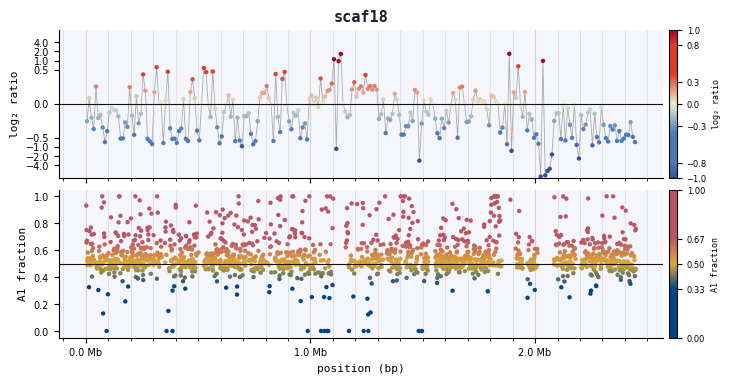

Saved → linear/UTEX2827_scaf18.linear.pdf


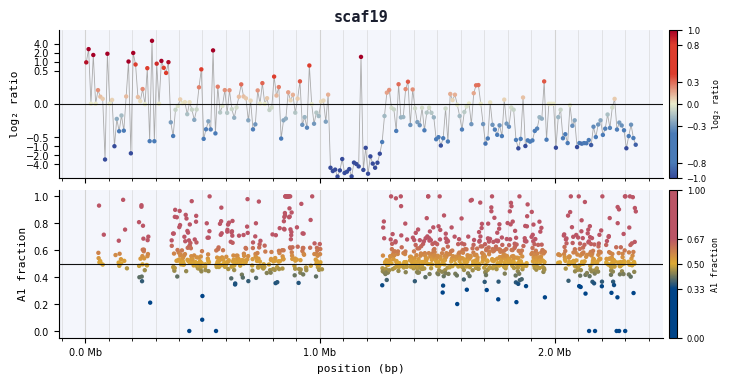

Saved → linear/UTEX2827_scaf19.linear.pdf


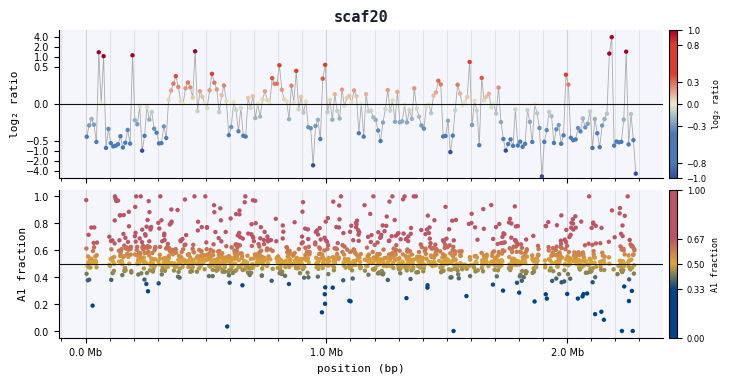

Saved → linear/UTEX2827_scaf20.linear.pdf


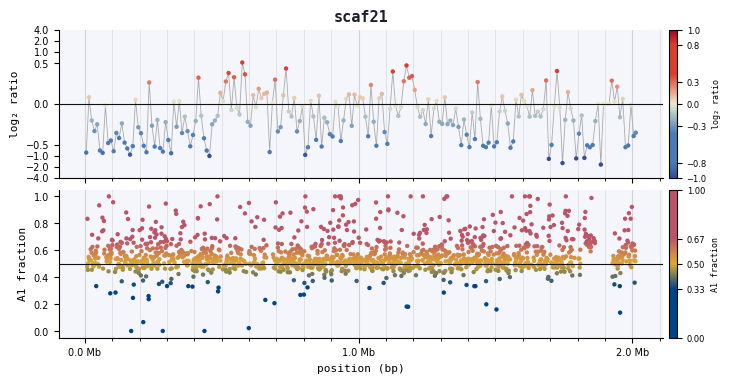

Saved → linear/UTEX2827_scaf21.linear.pdf


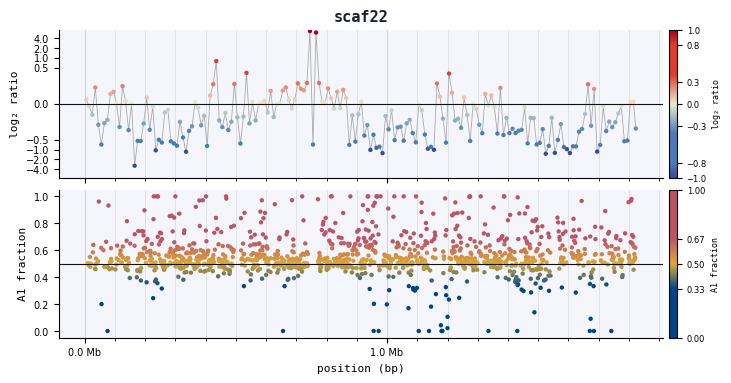

Saved → linear/UTEX2827_scaf22.linear.pdf


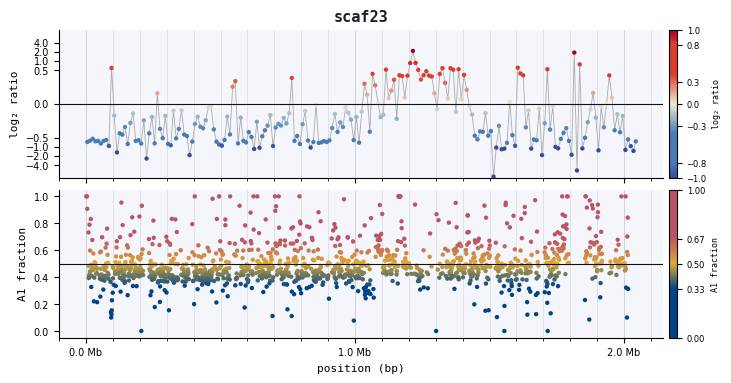

Saved → linear/UTEX2827_scaf23.linear.pdf


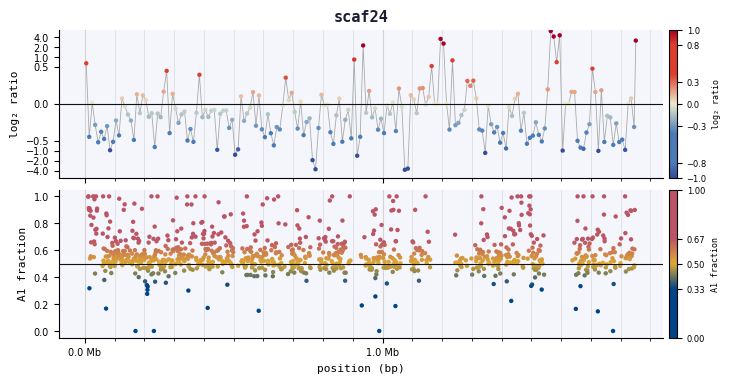

Saved → linear/UTEX2827_scaf24.linear.pdf


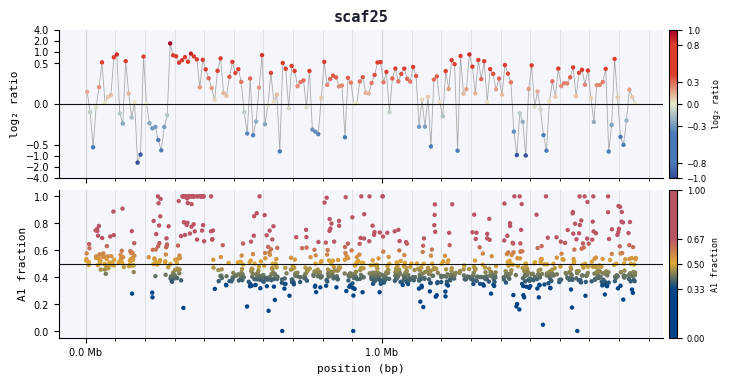

Saved → linear/UTEX2827_scaf25.linear.pdf


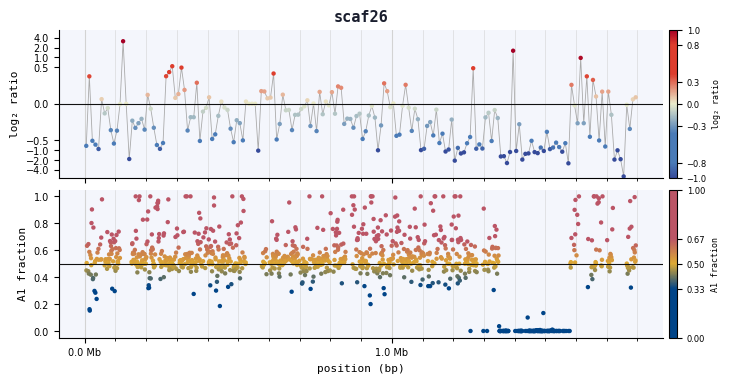

Saved → linear/UTEX2827_scaf26.linear.pdf


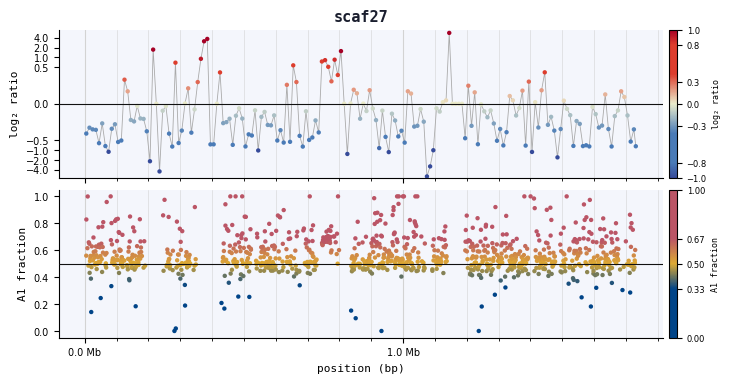

Saved → linear/UTEX2827_scaf27.linear.pdf


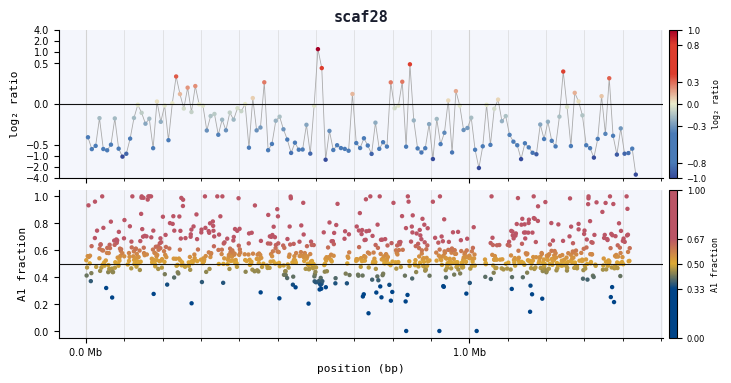

Saved → linear/UTEX2827_scaf28.linear.pdf


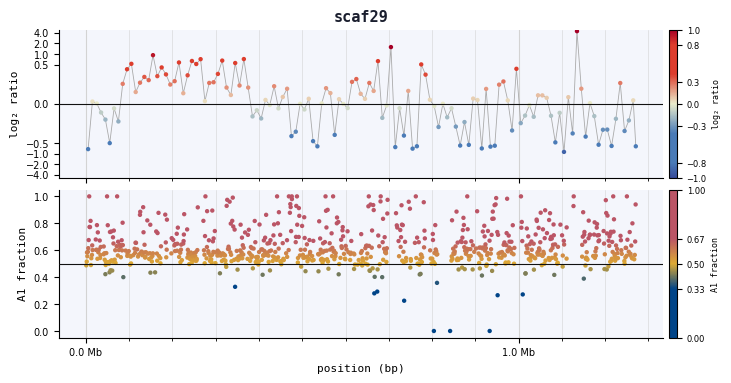

Saved → linear/UTEX2827_scaf29.linear.pdf


In [23]:
def load_log2_linear(path, scaffold, window_size=LINEAR_WINDOW):
    bins = defaultdict(list)
    with open(path) as f:
        reader = csv.DictReader(f, delimiter="\t")
        val_col = [c for c in reader.fieldnames if c not in ("chr","start","end")][0]
        for row in reader:
            try:
                if row["chr"] != scaffold:
                    continue
                start = int(row["start"])
                end   = int(row["end"])
                val   = float(row[val_col])
                mid   = (start + end) // 2
                bins[mid // window_size].append((mid, val))
            except (ValueError, KeyError):
                pass
    rows = sorted([(int(np.mean([p for p,v in pts])),
                    np.mean([v for p,v in pts]))
                   for pts in bins.values()])
    return np.array([p for p,v in rows]), np.array([v for p,v in rows])


def load_allelic_linear(path, scaffold, bin_size=LINEAR_BIN):
    bins = defaultdict(list)
    with open(path) as f:
        reader = csv.DictReader(f, delimiter="\t")
        for row in reader:
            try:
                if row["CHROM"] != scaffold:
                    continue
                pos = int(row["POS"])
                val = float(row["A1_frac"])
                bins[pos // bin_size].append((pos, val))
            except (ValueError, KeyError):
                pass
    rows = sorted([(int(np.mean([p for p,v in pts])),
                    np.mean([v for p,v in pts]))
                   for pts in bins.values()])
    return np.array([p for p,v in rows]), np.array([v for p,v in rows])


def log2_color(val, vmax=1.0):
    norm = (np.clip(val, -1.0, 1.0) + 1.0) / 2.0
    return LOG2_CMAP(norm)


for scaffold in SCAFFOLDS_OF_INTEREST:

    pos_l2r, vals_l2r = load_log2_linear(LOG2_PATH, scaffold)
    pos_al,  vals_al  = load_allelic_linear(ALLELIC_PATH, scaffold)

    # ── Y-axis range for log2 panel ────────────────────────────────────────────
    if LOG2_CLAMP is None:
        vmax = max(abs(vals_l2r.min()), abs(vals_l2r.max()))
    else:
        vmax = LOG2_CLAMP

    scaf_len  = sizes[scaffold]
    fig_width = max(8, scaf_len / 1e6 / LINEAR_MB_PER_INCH)
    fig, (ax_l2r, ax_al) = plt.subplots(2, 1,
                                         figsize=(fig_width, LINEAR_FIGSIZE_HEIGHT),
                                         sharex=True, facecolor="white",
                                         gridspec_kw={"hspace": 0.08})

    # ── Log2 ratio panel ───────────────────────────────────────────────────────
    colors_l2r = [log2_color(v) for v in vals_l2r]
    ax_l2r.plot(pos_l2r, vals_l2r, color="#aaaaaa", lw=0.6, zorder=2)
    ax_l2r.scatter(pos_l2r, vals_l2r, c=colors_l2r, s=10,
                   linewidths=0, zorder=3)
    ax_l2r.axhline(0, color=COLOR_BASELINE, lw=0.8, zorder=4)
    ax_l2r.set_yscale("symlog", linthresh=0.5)
    ax_l2r.set_ylim(-vmax * 1.1, vmax * 1.1)
    ax_l2r.set_yticks([-4, -2, -1, -0.5, 0, 0.5, 1, 2, 4])
    ax_l2r.yaxis.set_major_formatter(matplotlib.ticker.ScalarFormatter())
    ax_l2r.set_ylabel("log\u2082 ratio", fontsize=8, fontfamily="monospace")
    ax_l2r.set_title(scaffold, fontsize=11, fontweight="bold",
                     fontfamily="monospace", color="#1a1e2e", pad=6)
    ax_l2r.spines[["top","right"]].set_visible(False)
    ax_l2r.tick_params(labelsize=7)
    ax_l2r.set_facecolor("#f4f6fc")
    ax_l2r.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(1e6))
    ax_l2r.xaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(1e5))
    ax_l2r.yaxis.set_minor_locator(matplotlib.ticker.NullLocator())
    ax_l2r.grid(which="minor", axis="x", color="lightgrey", lw=0.4, zorder=1)
    ax_l2r.grid(which="major", axis="x", color="lightgrey", lw=0.8, zorder=1)

    sm_l2r = plt.cm.ScalarMappable(cmap=LOG2_CMAP, norm=Normalize(-1.0, 1.0))
    cb_l2r = fig.colorbar(sm_l2r, ax=ax_l2r, orientation="vertical",
                           fraction=0.015, pad=0.01)
    cb_l2r.set_ticks([-1, -0.8, -0.3, 0, 0.3, 0.8, 1])
    cb_l2r.ax.tick_params(labelsize=6)
    cb_l2r.set_label("log\u2082 ratio", fontsize=6, fontfamily="monospace")

    # ── Allelic fraction panel ─────────────────────────────────────────────────
    colors_al = ALLELIC_CMAP(vals_al)
    ax_al.scatter(pos_al, vals_al, c=colors_al, s=10,
                  linewidths=0, zorder=3)
    ax_al.axhline(0.5, color=COLOR_BASELINE, lw=0.8, zorder=4)
    ax_al.set_ylim(-0.05, 1.05)
    ax_al.set_ylabel("A1 fraction", fontsize=8, fontfamily="monospace")
    ax_al.set_xlabel("position (bp)", fontsize=8, fontfamily="monospace")
    ax_al.spines[["top","right"]].set_visible(False)
    ax_al.tick_params(labelsize=7)
    ax_al.set_facecolor("#f4f6fc")
    ax_al.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(1e6))
    ax_al.xaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(1e5))
    ax_al.yaxis.set_minor_locator(matplotlib.ticker.NullLocator())
    ax_al.grid(which="minor", axis="x", color="lightgrey", lw=0.4, zorder=1)
    ax_al.grid(which="major", axis="x", color="lightgrey", lw=0.8, zorder=1)

    sm_al = plt.cm.ScalarMappable(cmap=ALLELIC_CMAP, norm=Normalize(0, 1))
    cb_al = fig.colorbar(sm_al, ax=ax_al, orientation="vertical",
                          fraction=0.015, pad=0.01)
    cb_al.set_ticks([0, 0.33, 0.5, 0.67, 1])
    cb_al.ax.tick_params(labelsize=6)
    cb_al.set_label("A1 fraction", fontsize=6, fontfamily="monospace")

    # ── x-axis Mb formatting ───────────────────────────────────────────────────
    ax_al.xaxis.set_major_formatter(
        matplotlib.ticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f} Mb"))

    plt.show()

    out = LINEAR_OUTPUT.replace("{scaffold}", scaffold).replace("{strain}", STRAIN)
    fig.savefig(out, dpi=DPI, bbox_inches="tight", facecolor="white")
    print(f"Saved → {out}")